In [1]:
cd /content/drive/MyDrive/ColabNotebooks

/content/drive/MyDrive/ColabNotebooks


In [2]:
# 한글 폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 1 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (11.6 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 117528 files and direct

In [11]:
# [MP3-1] 머신러닝 모델 학습

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
import os


if os.path.exists("busan_bus_cleaned.csv"):
    df_final = pd.read_csv("busan_bus_cleaned.csv")

    # 특징 타겟 분리
    # 입력 데이터: 시간, 정류장순서, 요일, 노선번호
    X = df_final[['tzon', 'sttn_seq', 'day_num', 'route_num']]
    y = df_final['cgst']

    # Validation 데이터와 test 데이터 분리 (8:2)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # 데이터 스케일링
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # 모델 생성
    model = LinearRegression()
    model.fit(X_train_scaled, y_train)

    # 5. 모델 평가
    y_pred = model.predict(X_test_scaled)
    r2 = r2_score(y_test, y_pred)


    print("[MP3-1] 모델 학습 결과")
    print(f"예측 정확도-R2 Score : {r2:.4f}")

[MP3-1] 모델 학습 결과
예측 정확도-R2 Score : 0.2338


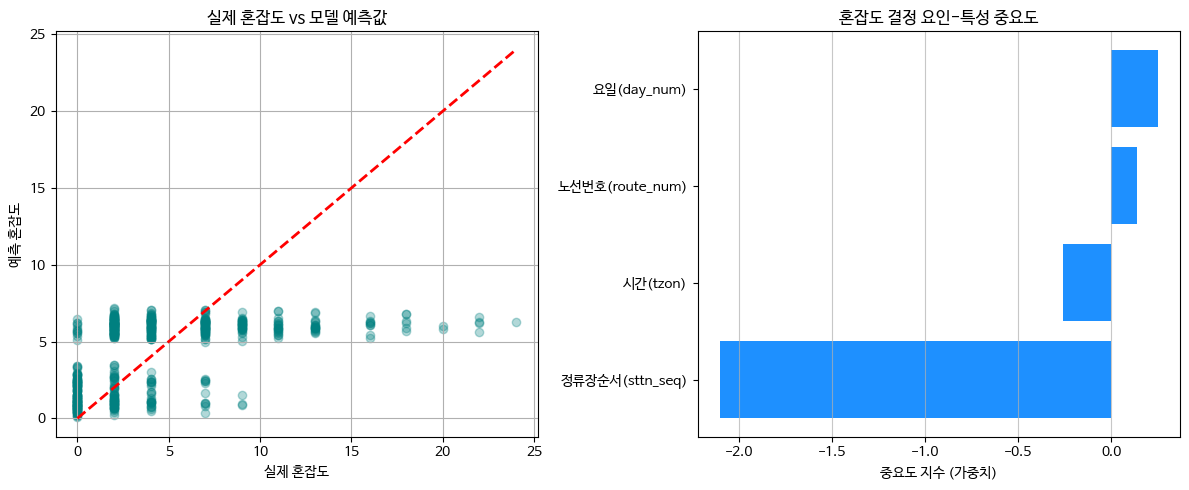

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

# 실제값 vs 예측값 시각화
plt.figure(figsize=(12, 5))

# 실제값 vs 예측값
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.3, color='teal')

# y=x 그리기
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

plt.title("실제 혼잡도 vs 모델 예측값")
plt.xlabel("실제 혼잡도")
plt.ylabel("예측 혼잡도")
plt.grid()

# 특성 중요도
plt.subplot(1, 2, 2)

# coef_(회귀 계수)
importances = model.coef_
feature_names = ['시간(tzon)', '정류장순서(sttn_seq)', '요일(day_num)', '노선번호(route_num)']
indices = np.argsort(importances)

# 가로 막대 그래프 그리기
plt.barh(range(len(indices)), importances[indices], color='dodgerblue', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.title("혼잡도 결정 요인-특성 중요도")
plt.xlabel("중요도 지수 (가중치)")
plt.grid(axis='x', alpha=0.7)

plt.tight_layout()
plt.show()